# Superstore Data Analysis Capstone

**Business Question:** How can the business improve sales and profitability across regions and product categories?

Dataset: Sample Superstore (9,994 rows).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = '../day-05/data/Sample - Superstore.csv'
df = pd.read_csv(DATA_PATH, encoding='cp1252')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 1. Data Cleaning
Check missing values, duplicates, and data types.

In [2]:
print('Dataset shape:', df.shape)
print('\nMissing values:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('\nData types:')
print(df.dtypes)

Dataset shape: (9994, 21)

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate rows: 0

Data types:
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit       

In [3]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df = df.drop_duplicates().copy()
df['Postal Code'] = df['Postal Code'].astype('Int64')
print('Cleaned shape:', df.shape)
df.head()

Cleaned shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. Exploratory Data Analysis (EDA)
Explore sales and profit by region, category, and sub-category.

In [4]:
print('Sales:', round(df['Sales'].sum(), 2))
print('Profit:', round(df['Profit'].sum(), 2))
print('Average order line sales:', round(df['Sales'].mean(), 2))
print('\nSales and profit by region:')
print(df.groupby('Region')[['Sales', 'Profit']].sum().round(2))
print('\nSales and profit by category:')
print(df.groupby('Category')[['Sales', 'Profit']].sum().round(2))

Sales: 2297200.86
Profit: 286397.02
Average order line sales: 229.86

Sales and profit by region:
             Sales     Profit
Region                       
Central  501239.89   39706.36
East     678781.24   91522.78
South    391721.90   46749.43
West     725457.82  108418.45

Sales and profit by category:
                     Sales     Profit
Category                             
Furniture        741999.80   18451.27
Office Supplies  719047.03  122490.80
Technology       836154.03  145454.95


## 3. Data Visualization

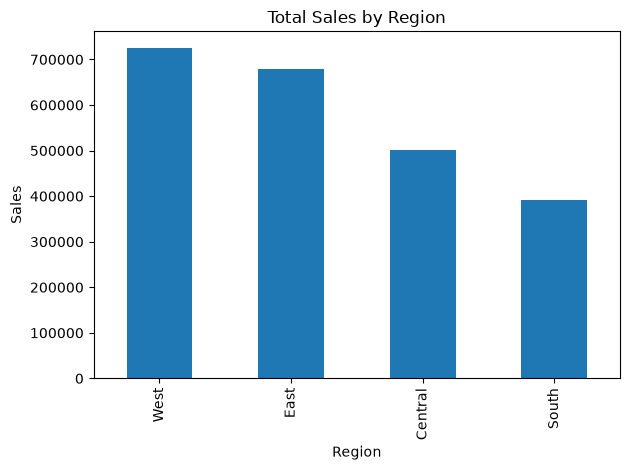

In [5]:
sales_region = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
sales_region.plot(kind='bar', title='Total Sales by Region', ylabel='Sales', xlabel='Region')
plt.tight_layout()
plt.show()

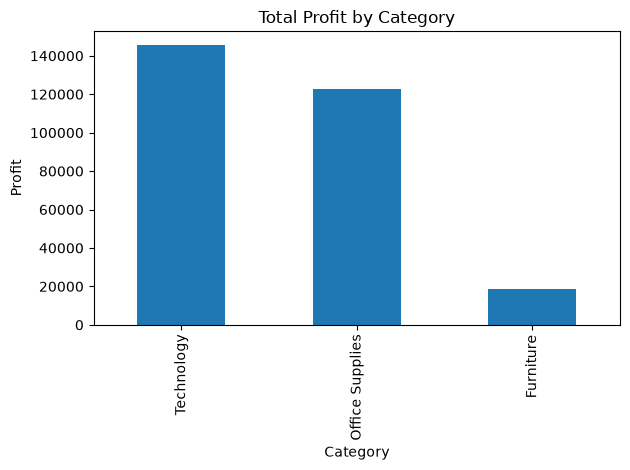

In [6]:
profit_category = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)
profit_category.plot(kind='bar', title='Total Profit by Category', ylabel='Profit', xlabel='Category')
plt.tight_layout()
plt.show()

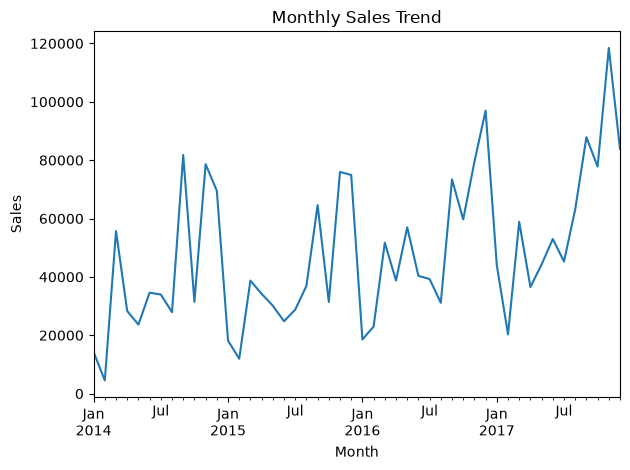

In [7]:
monthly_sales = df.set_index('Order Date').resample('ME')['Sales'].sum()
monthly_sales.plot(kind='line', title='Monthly Sales Trend', ylabel='Sales', xlabel='Month')
plt.tight_layout()
plt.show()

## 4. Statistical Analysis
Examine the relationship between discount and profit using correlation.

In [8]:
correlation = df['Discount'].corr(df['Profit'])
print('Correlation between Discount and Profit:', round(correlation, 3))
print('\nProfit summary:')
print(df['Profit'].describe())

Correlation between Discount and Profit: -0.219

Profit summary:
count    9994.000000
mean       28.656896
std       234.260108
min     -6599.978000
25%         1.728750
50%         8.666500
75%        29.364000
max      8399.976000
Name: Profit, dtype: float64


## 5. Business Recommendations
1. Review low-profit and loss-making sub-categories before increasing sales promotions.
2. Compare regional sales and profit to identify areas that need improvement.
3. Monitor discounts and their relationship with profit to avoid unnecessary margin loss.